# Visualisasi Data dengan Matplotlib & Seaborn
## Analisis Penjualan Mobil DasAutomobile pada Periode Resesi dan Non-Resesi

Dataset: `historical_automobile_sales.csv` (penjualan bulanan, 1980 dan seterusnya).

| Kolom | Keterangan |
|---|---|
| Year, Month, Date | Waktu pengamatan |
| Recession | 1 = periode resesi, 0 = non-resesi |
| Automobile_Sales | Rata-rata penjualan mobil bulanan |
| Advertising_Expenditure | Pengeluaran iklan DasAutomobile |
| Vehicle_Type | Jenis kendaraan |
| Price | Harga rata-rata kendaraan |
| GDP | Produk Domestik Bruto |
| unemployment_rate | Tingkat pengangguran |
| Seasonality_Weight | Bobot musiman |
| Consumer_Confidence | Indeks kepercayaan konsumen |

## 0. Import library dan muat data

In [1]:
import numpy as np
%pip install pandas
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

sns.set_theme(style="whitegrid")

URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/historical_automobile_sales.csv"
df = pd.read_csv(URL)

# Rapikan nama kolom (beberapa versi dataset menulis Unemployment_Rate dengan huruf besar)
df.columns = df.columns.str.strip()
df = df.rename(columns={c: "unemployment_rate" for c in df.columns if c.lower() == "unemployment_rate"})

print("Dimensi data:", df.shape)
df.head()

Dimensi data: (528, 15)


,Date,Year,Month,Recession,Consumer_Confidence,Seasonality_Weight,Price,Advertising_Expenditure,Competition,GDP,Growth_Rate,unemployment_rate,Automobile_Sales,Vehicle_Type,City
0,1/31/1980,1980,Jan,1,108.24,0.50,27483.571,1558,7,60.223,0.010000,5.4,456.0,Supperminicar,Georgia
1,2/29/1980,1980,Feb,1,98.75,0.75,24308.678,3048,4,45.986,-0.309594,4.8,555.9,Supperminicar,New York
2,3/31/1980,1980,Mar,1,107.48,0.20,28238.443,3137,3,35.141,-0.308614,3.4,620.0,Mediumfamilycar,New York
3,4/30/1980,1980,Apr,1,115.01,1.00,32615.149,1653,7,45.673,0.230596,4.2,702.8,Supperminicar,Illinois
4,5/31/1980,1980,May,1,98.72,0.20,23829.233,1319,4,52.997,0.138197,5.3,770.4,Smallfamiliycar,California


In [2]:
print("Nilai kosong per kolom:")
print(df.isnull().sum())
print()
print("Jumlah baris per periode:")
print(df["Recession"].map({0: "Non-recession", 1: "Recession"}).value_counts())
print()
print("Jenis kendaraan:", df["Vehicle_Type"].unique())

Nilai kosong per kolom:
Date                       0
Year                       0
Month                      0
Recession                  0
Consumer_Confidence        0
Seasonality_Weight         0
Price                      0
Advertising_Expenditure    0
Competition                0
GDP                        0
Growth_Rate                0
unemployment_rate          0
Automobile_Sales           0
Vehicle_Type               0
City                       0
dtype: int64

Jumlah baris per periode:
Recession
Non-recession    415
Recession        113
Name: count, dtype: int64

Jenis kendaraan: ['Supperminicar' 'Mediumfamilycar' 'Smallfamiliycar' 'Sports'
 'Executivecar']


## 1.1 Grafik garis: fluktuasi penjualan mobil dari tahun ke tahun
Rata-rata penjualan per tahun. Tahun yang memiliki bulan resesi diberi blok merah.

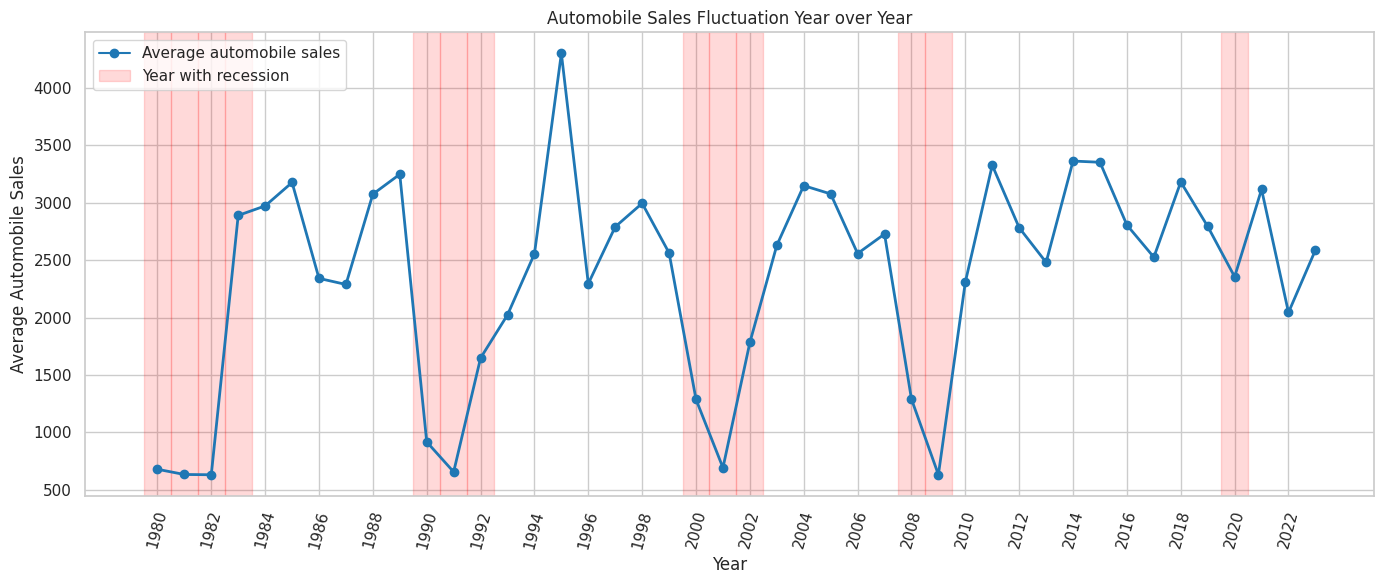

Tahun penjualan tertinggi : 1995 (4300.2)
Tahun penjualan terendah  : 1982 (631.1)


In [3]:
yearly_sales = df.groupby("Year")["Automobile_Sales"].mean()
recession_years = sorted(df.loc[df["Recession"] == 1, "Year"].unique())

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(yearly_sales.index, yearly_sales.values, marker="o", linewidth=2, color="tab:blue")
for y in recession_years:
    ax.axvspan(y - 0.5, y + 0.5, color="red", alpha=0.15)

ax.set_xticks(np.arange(df["Year"].min(), df["Year"].max() + 1, 2))
ax.tick_params(axis="x", rotation=75)
ax.set_xlabel("Year")
ax.set_ylabel("Average Automobile Sales")
ax.set_title("Automobile Sales Fluctuation Year over Year")
ax.legend(handles=[
    plt.Line2D([0], [0], color="tab:blue", marker="o", label="Average automobile sales"),
    mpatches.Patch(color="red", alpha=0.15, label="Year with recession"),
], loc="upper left")
plt.tight_layout()
plt.show()

print(f"Tahun penjualan tertinggi : {yearly_sales.idxmax()} ({yearly_sales.max():.1f})")
print(f"Tahun penjualan terendah  : {yearly_sales.idxmin()} ({yearly_sales.min():.1f})")

## 1.2 Grafik garis: pengeluaran iklan vs penjualan mobil (periode non-resesi)
Dua sumbu-y dipakai karena skala kedua variabel berbeda.

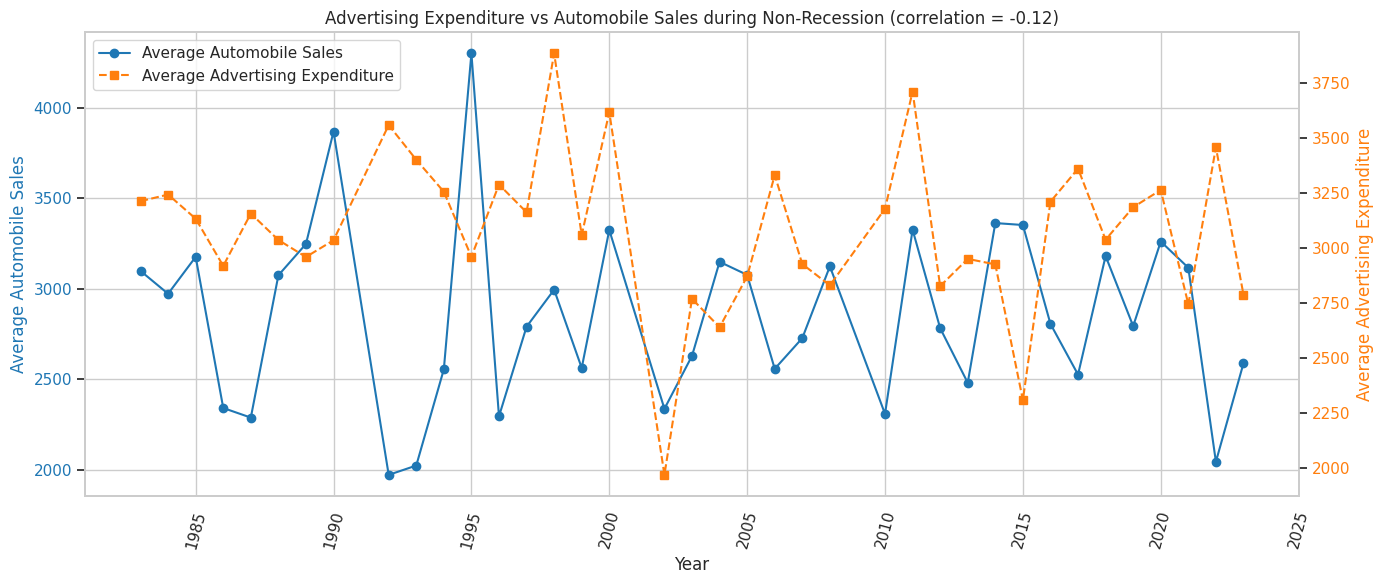

Korelasi pengeluaran iklan dan penjualan (non-resesi): -0.124


In [4]:
non_rec = df[df["Recession"] == 0]
ad_sales = non_rec.groupby("Year")[["Advertising_Expenditure", "Automobile_Sales"]].mean()
corr_ad = ad_sales["Advertising_Expenditure"].corr(ad_sales["Automobile_Sales"])

fig, ax1 = plt.subplots(figsize=(14, 6))
l1 = ax1.plot(ad_sales.index, ad_sales["Automobile_Sales"], marker="o",
              color="tab:blue", label="Average Automobile Sales")
ax1.set_xlabel("Year")
ax1.set_ylabel("Average Automobile Sales", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")
ax1.tick_params(axis="x", rotation=75)

ax2 = ax1.twinx()
l2 = ax2.plot(ad_sales.index, ad_sales["Advertising_Expenditure"], marker="s", linestyle="--",
              color="tab:orange", label="Average Advertising Expenditure")
ax2.set_ylabel("Average Advertising Expenditure", color="tab:orange")
ax2.tick_params(axis="y", labelcolor="tab:orange")
ax2.grid(False)

lines = l1 + l2
ax1.legend(lines, [l.get_label() for l in lines], loc="upper left")
ax1.set_title(f"Advertising Expenditure vs Automobile Sales during Non-Recession (correlation = {corr_ad:.2f})")
plt.tight_layout()
plt.show()

print(f"Korelasi pengeluaran iklan dan penjualan (non-resesi): {corr_ad:.3f}")

## 1.3 Grafik batang: penjualan per jenis kendaraan, resesi vs non-resesi

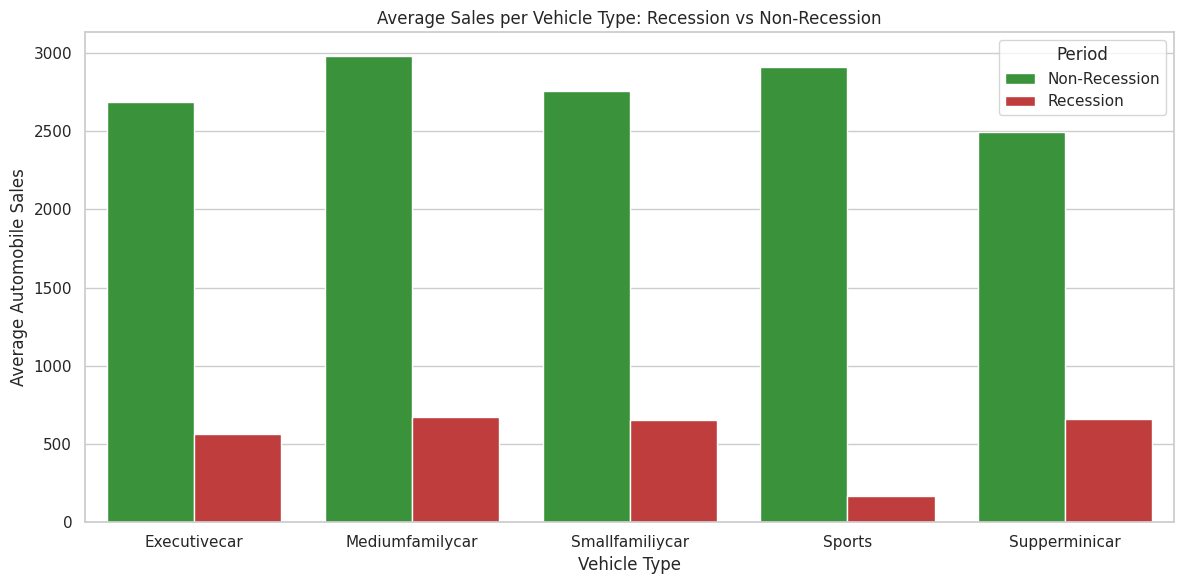

Period,Non-Recession,Recession,Change (%)
Vehicle_Type,,,
Executivecar,2686.44,564.00,-79.01
Mediumfamilycar,2981.50,674.85,-77.37
Smallfamiliycar,2752.66,650.73,-76.36
Sports,2910.64,170.33,-94.15
Supperminicar,2495.24,659.27,-73.58


In [5]:
vt = (df.groupby(["Recession", "Vehicle_Type"])["Automobile_Sales"].mean().reset_index())
vt["Period"] = vt["Recession"].map({1: "Recession", 0: "Non-Recession"})

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=vt, x="Vehicle_Type", y="Automobile_Sales", hue="Period",
            palette={"Recession": "tab:red", "Non-Recession": "tab:green"}, ax=ax)
ax.set_xlabel("Vehicle Type")
ax.set_ylabel("Average Automobile Sales")
ax.set_title("Average Sales per Vehicle Type: Recession vs Non-Recession")
plt.tight_layout()
plt.show()

pivot = vt.pivot(index="Vehicle_Type", columns="Period", values="Automobile_Sales")
pivot["Change (%)"] = (pivot["Recession"] - pivot["Non-Recession"]) / pivot["Non-Recession"] * 100
pivot.round(2)

## 1.4 Subplot: variasi GDP pada periode resesi dan non-resesi

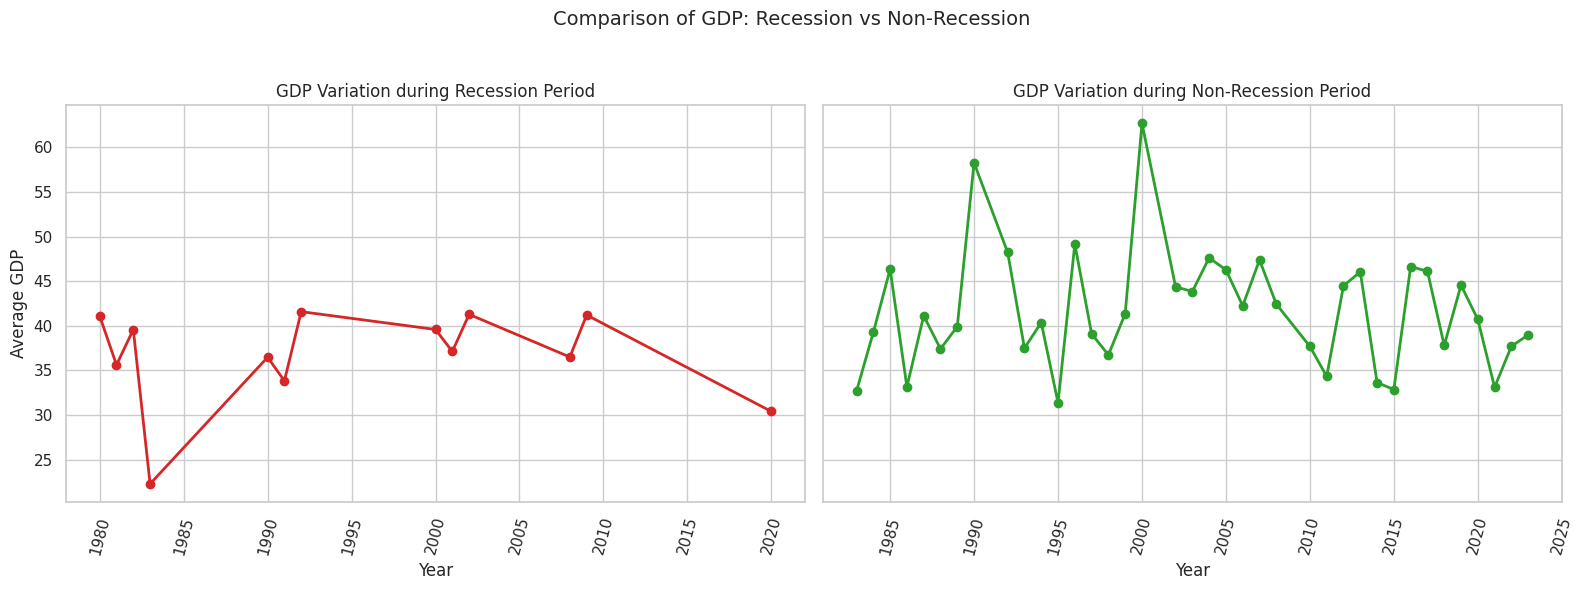

In [6]:
gdp = df.groupby(["Recession", "Year"])["GDP"].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
settings = [(1, "Recession", "tab:red"), (0, "Non-Recession", "tab:green")]

for ax, (flag, label, color) in zip(axes, settings):
    sub = gdp[gdp["Recession"] == flag]
    ax.plot(sub["Year"], sub["GDP"], marker="o", color=color, linewidth=2)
    ax.set_title(f"GDP Variation during {label} Period")
    ax.set_xlabel("Year")
    ax.tick_params(axis="x", rotation=75)

axes[0].set_ylabel("Average GDP")
fig.suptitle("Comparison of GDP: Recession vs Non-Recession", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## 1.5 Grafik gelembung: dampak musiman pada penjualan mobil
Sumbu-x = bulan, sumbu-y = rata-rata penjualan, ukuran dan warna gelembung = rata-rata `Seasonality_Weight`.

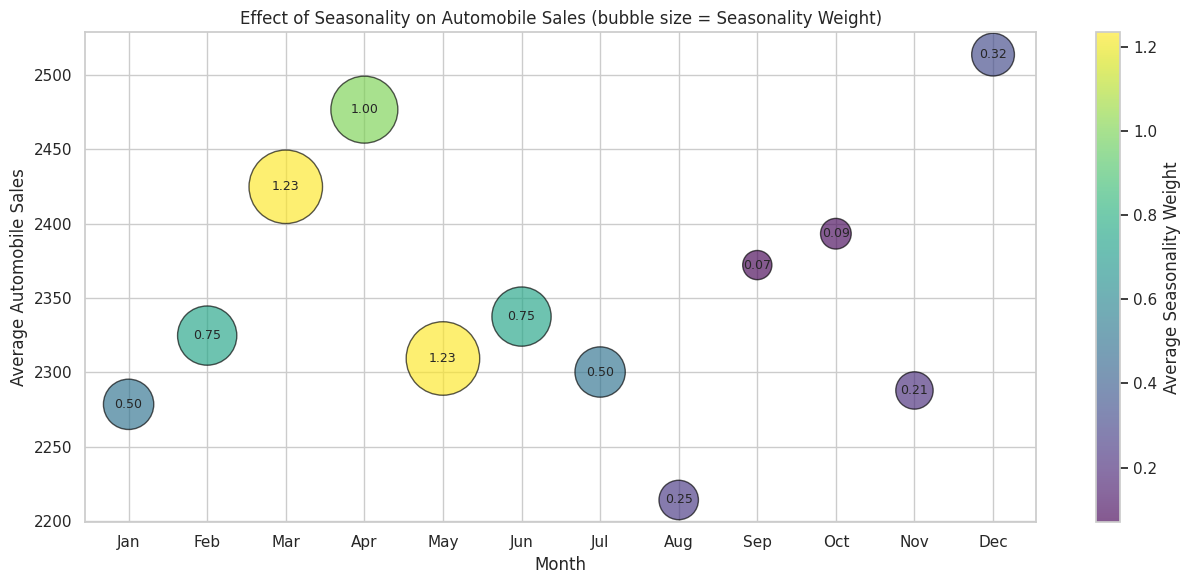

In [7]:
month_order = df["Month"].drop_duplicates().tolist()   # urutan kemunculan = urutan kalender
seasonal = (df.groupby("Month")
              .agg(Sales=("Automobile_Sales", "mean"), Seasonality=("Seasonality_Weight", "mean"))
              .reindex(month_order)
              .reset_index())

max_w = seasonal["Seasonality"].max() or 1
sizes = 300 + 2500 * seasonal["Seasonality"] / max_w

fig, ax = plt.subplots(figsize=(13, 6))
sc = ax.scatter(seasonal["Month"], seasonal["Sales"], s=sizes, c=seasonal["Seasonality"],
                cmap="viridis", alpha=0.65, edgecolors="black")
for _, row in seasonal.iterrows():
    ax.annotate(f"{row['Seasonality']:.2f}", (row["Month"], row["Sales"]),
                ha="center", va="center", fontsize=9)

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Average Seasonality Weight")
ax.set_xlabel("Month")
ax.set_ylabel("Average Automobile Sales")
ax.set_title("Effect of Seasonality on Automobile Sales (bubble size = Seasonality Weight)")
plt.tight_layout()
plt.show()

## 1.6 Grafik sebar: harga rata-rata kendaraan vs volume penjualan saat resesi

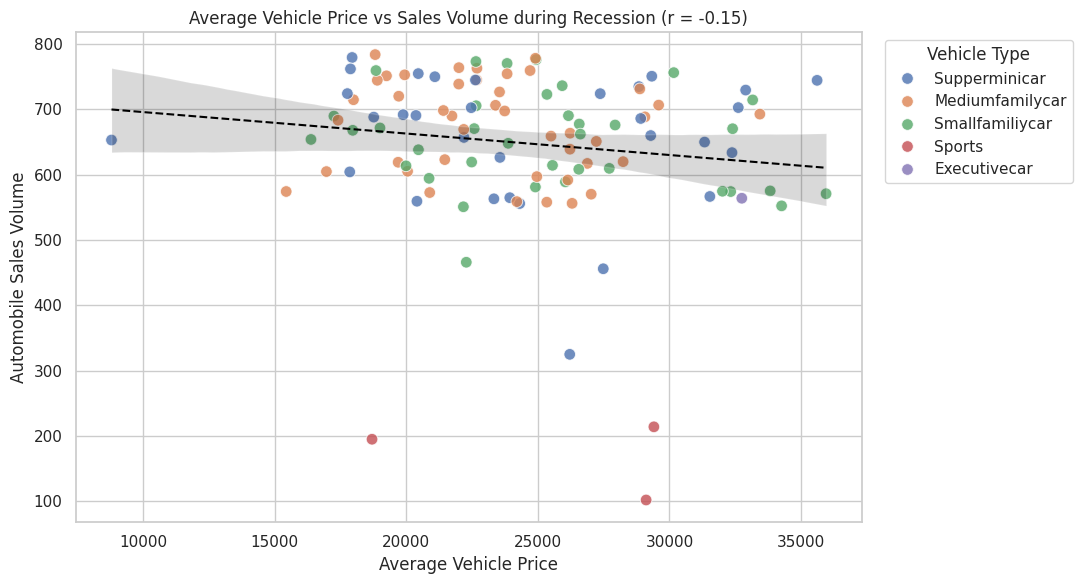

Korelasi harga vs penjualan (resesi): -0.147


In [8]:
rec = df[df["Recession"] == 1]
corr_price = rec["Price"].corr(rec["Automobile_Sales"])

fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(data=rec, x="Price", y="Automobile_Sales", hue="Vehicle_Type",
                s=70, alpha=0.8, ax=ax)
sns.regplot(data=rec, x="Price", y="Automobile_Sales", scatter=False,
            color="black", line_kws={"linestyle": "--", "linewidth": 1.5}, ax=ax)
ax.set_xlabel("Average Vehicle Price")
ax.set_ylabel("Automobile Sales Volume")
ax.set_title(f"Average Vehicle Price vs Sales Volume during Recession (r = {corr_price:.2f})")
ax.legend(title="Vehicle Type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print(f"Korelasi harga vs penjualan (resesi): {corr_price:.3f}")

## 1.7 Grafik pai: porsi pengeluaran iklan resesi vs non-resesi

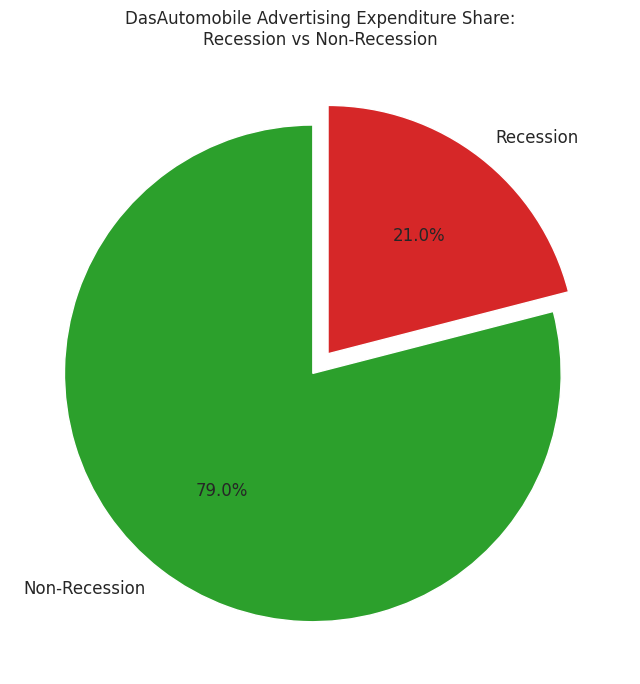

Recession
Non-Recession    1279707
Recession         339910
Name: Advertising_Expenditure, dtype: int64


In [9]:
ad_share = (df.groupby("Recession")["Advertising_Expenditure"].sum()
              .rename(index={0: "Non-Recession", 1: "Recession"}))

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(ad_share.values, labels=ad_share.index, autopct="%1.1f%%", startangle=90,
       colors=["tab:green" if i == "Non-Recession" else "tab:red" for i in ad_share.index],
       explode=[0.05] * len(ad_share), textprops={"fontsize": 12})
ax.set_title("DasAutomobile Advertising Expenditure Share:\nRecession vs Non-Recession")
plt.tight_layout()
plt.show()

print(ad_share.round(0))

## 1.8 Grafik pai: total pengeluaran iklan per jenis kendaraan saat resesi

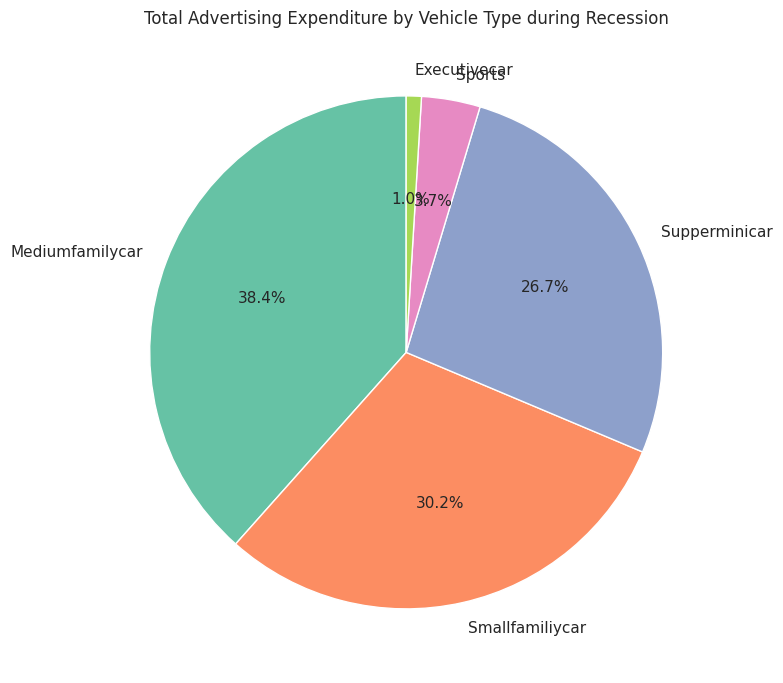

Vehicle_Type
Mediumfamilycar    130612
Smallfamiliycar    102759
Supperminicar       90728
Sports              12568
Executivecar         3243
Name: Advertising_Expenditure, dtype: int64


In [10]:
rec_ad = (df[df["Recession"] == 1]
            .groupby("Vehicle_Type")["Advertising_Expenditure"].sum()
            .sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(rec_ad.values, labels=rec_ad.index, autopct="%1.1f%%", startangle=90,
       colors=sns.color_palette("Set2", len(rec_ad)), textprops={"fontsize": 11})
ax.set_title("Total Advertising Expenditure by Vehicle Type during Recession")
plt.tight_layout()
plt.show()

print(rec_ad.round(0))

## 1.9 Grafik garis: pengaruh tingkat pengangguran terhadap jenis kendaraan dan penjualan (resesi)

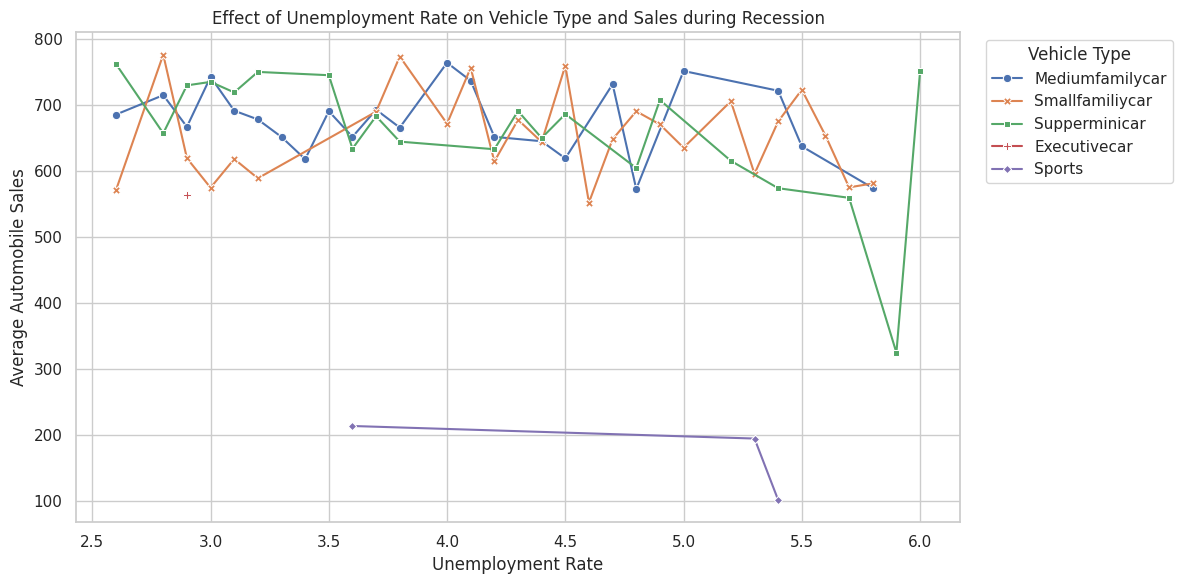

In [11]:
rec = df[df["Recession"] == 1]
unemp = (rec.groupby(["unemployment_rate", "Vehicle_Type"])["Automobile_Sales"]
            .mean().reset_index())

fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(data=unemp, x="unemployment_rate", y="Automobile_Sales",
             hue="Vehicle_Type", style="Vehicle_Type", markers=True, dashes=False, ax=ax)
ax.set_xlabel("Unemployment Rate")
ax.set_ylabel("Average Automobile Sales")
ax.set_title("Effect of Unemployment Rate on Vehicle Type and Sales during Recession")
ax.legend(title="Vehicle Type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 2. Ringkasan hasil analisis
Sel berikut merangkum hasil bagian 1.1–1.9 dengan memakai langsung variabel dari bagian tersebut (`yearly_sales`, `pivot`, `seasonal`, `ad_share`, `rec_ad`, `corr_ad`, `corr_price`), sehingga angkanya identik dengan yang tercetak di tiap bagian. Angka yang dicetak di sini menjadi rujukan untuk dashboard, README, dan caption. Tabel di akhir juga menampilkan **jumlah bulan resesi (n)** tiap jenis kendaraan, yang penting untuk membaca hasil Sports dan Executivecar.

In [12]:
# ===== 2. Ringkasan hasil analisis (diambil langsung dari variabel pada bagian 1.1–1.9) =====
# Jalankan bagian 1 lebih dulu (Kernel > Restart & Run All), karena sel ini memakai hasilnya.
non = df[df["Recession"] == 0]
rec = df[df["Recession"] == 1]

# --- Ringkasan data (sama dengan pengecekan awal) ---
n_rows, n_rec, n_non = len(df), len(rec), len(non)
pct_rec, pct_non = n_rec / n_rows * 100, n_non / n_rows * 100

# --- Gabungan semua jenis kendaraan (pelengkap bagian 1.3) ---
avg_non   = non["Automobile_Sales"].mean()
avg_rec   = rec["Automobile_Sales"].mean()
chg_total = (avg_rec / avg_non - 1) * 100

# --- Bagian 1.1: penjualan per tahun ---
yr_is_rec  = yearly_sales.index.isin(recession_years)
yr_avg_rec = yearly_sales[yr_is_rec].mean()
yr_avg_non = yearly_sales[~yr_is_rec].mean()
best_year, worst_year = yearly_sales.idxmax(), yearly_sales.idxmin()

# --- Bagian 1.5: penjualan dan bobot musiman per bulan ---
season      = seasonal.set_index("Month")
best_month  = season["Sales"].idxmax()
worst_month = season["Sales"].idxmin()
month_gap   = (season["Sales"].max() / season["Sales"].min() - 1) * 100

# --- Bagian 1.3: perubahan penjualan per jenis kendaraan ---
vt_chg = pivot["Change (%)"].sort_values(ascending=False)   # paling kecil turunnya di atas
vt_n   = rec["Vehicle_Type"].value_counts()                 # jumlah bulan resesi per jenis kendaraan

# --- Bagian 1.7 dan 1.8: iklan ---
ad_rec_pct = ad_share["Recession"] / ad_share.sum() * 100
vt_ad_pct  = rec_ad / rec_ad.sum() * 100

# --- Bagian 1.2 dan 1.6: korelasi (nilai yang sama dengan yang dicetak di bagian tersebut) ---
r_ad, r_price = corr_ad, corr_price

def kekuatan_korelasi(r):
    a = abs(r)
    return "sangat lemah" if a < 0.1 else "lemah" if a < 0.3 else "sedang" if a < 0.5 else "kuat"

def label_korelasi(r):
    return f"{kekuatan_korelasi(r)} {'negatif' if r < 0 else 'positif'}"

# --- Cetak ringkasan: cocokkan dengan dashboard, README, dan caption ---
print(f"Jumlah baris data             : {n_rows}")
print(f"Bulan resesi / non-resesi     : {n_rec} ({pct_rec:.1f}%) / {n_non} ({pct_non:.1f}%)")
print(f"Rata-rata penjualan non-resesi: {avg_non:.0f}")
print(f"Rata-rata penjualan resesi    : {avg_rec:.0f}")
print(f"Perubahan saat resesi         : {chg_total:.1f}%")
print(f"[1.1] Tahun tertinggi / terendah: {best_year} ({yearly_sales.max():.1f}) / {worst_year} ({yearly_sales.min():.1f})")
print(f"[1.1] Rata-rata tahunan, tahun resesi vs lainnya: {yr_avg_rec:.0f} vs {yr_avg_non:.0f}")
print(f"[1.5] Bulan tertinggi / terendah: {best_month} ({season['Sales'].max():.0f}) / {worst_month} ({season['Sales'].min():.0f}), selisih {month_gap:.1f}%")
print(f"[1.7] Porsi iklan saat resesi   : {ad_rec_pct:.1f}%")
print(f"[1.8] Porsi iklan terbesar saat resesi: {rec_ad.index[0]} ({vt_ad_pct.iloc[0]:.1f}%)")
print(f"[1.2] r iklan vs penjualan (non-resesi) : {r_ad:.3f} -> {label_korelasi(r_ad)}")
print(f"[1.6] r harga vs penjualan (resesi)     : {r_price:.3f} -> {label_korelasi(r_price)}")
print()

tabel_kendaraan = pd.DataFrame({
    "Non-resesi": pivot["Non-Recession"],
    "Resesi": pivot["Recession"],
    "Perubahan (%)": pivot["Change (%)"],
    "Jumlah bulan resesi (n)": vt_n,
    "Porsi iklan resesi (%)": vt_ad_pct,
}).round(2).loc[vt_chg.index]
tabel_kendaraan

Jumlah baris data             : 528
Bulan resesi / non-resesi     : 113 (21.4%) / 415 (78.6%)
Rata-rata penjualan non-resesi: 2817
Rata-rata penjualan resesi    : 649
Perubahan saat resesi         : -77.0%
[1.1] Tahun tertinggi / terendah: 1995 (4300.2) / 1982 (631.1)
[1.1] Rata-rata tahunan, tahun resesi vs lainnya: 1238 vs 2820
[1.5] Bulan tertinggi / terendah: Dec (2514) / Aug (2214), selisih 13.5%
[1.7] Porsi iklan saat resesi   : 21.0%
[1.8] Porsi iklan terbesar saat resesi: Mediumfamilycar (38.4%)
[1.2] r iklan vs penjualan (non-resesi) : -0.124 -> lemah negatif
[1.6] r harga vs penjualan (resesi)     : -0.147 -> lemah negatif



,Non-resesi,Resesi,Perubahan (%),Jumlah bulan resesi (n),Porsi iklan resesi (%)
Vehicle_Type,,,,,
Supperminicar,2495.24,659.27,-73.58,31,26.69
Smallfamiliycar,2752.66,650.73,-76.36,36,30.23
Mediumfamilycar,2981.50,674.85,-77.37,42,38.43
Executivecar,2686.44,564.00,-79.01,1,0.95
Sports,2910.64,170.33,-94.15,3,3.70


## 3. Dashboard ringkasan: Dampak Resesi pada Penjualan DasAutomobile
Dashboard disusun dari hasil bagian 1 dan 2, lalu disimpan sebagai `images/dashboard.png` (dipakai di README dan postingan LinkedIn). Asal data tiap panel:

| Panel | Sumber |
|---|---|
| Penjualan per Bulan (dan bobot musiman) | 1.5 |
| Penjualan Rata-rata per Tahun | 1.1 |
| Alokasi Iklan saat Resesi | 1.8 |
| Perubahan Penjualan per jenis kendaraan | 1.3 |
| Harga vs Penjualan saat Resesi | 1.6 |
| Porsi Iklan resesi vs non-resesi | 1.7 |
| Korelasi iklan vs penjualan (di ringkasan) | 1.2 |

Ubah `ANALIS` atau `TAMPILKAN_CATATAN_N` di awal sel jika perlu.

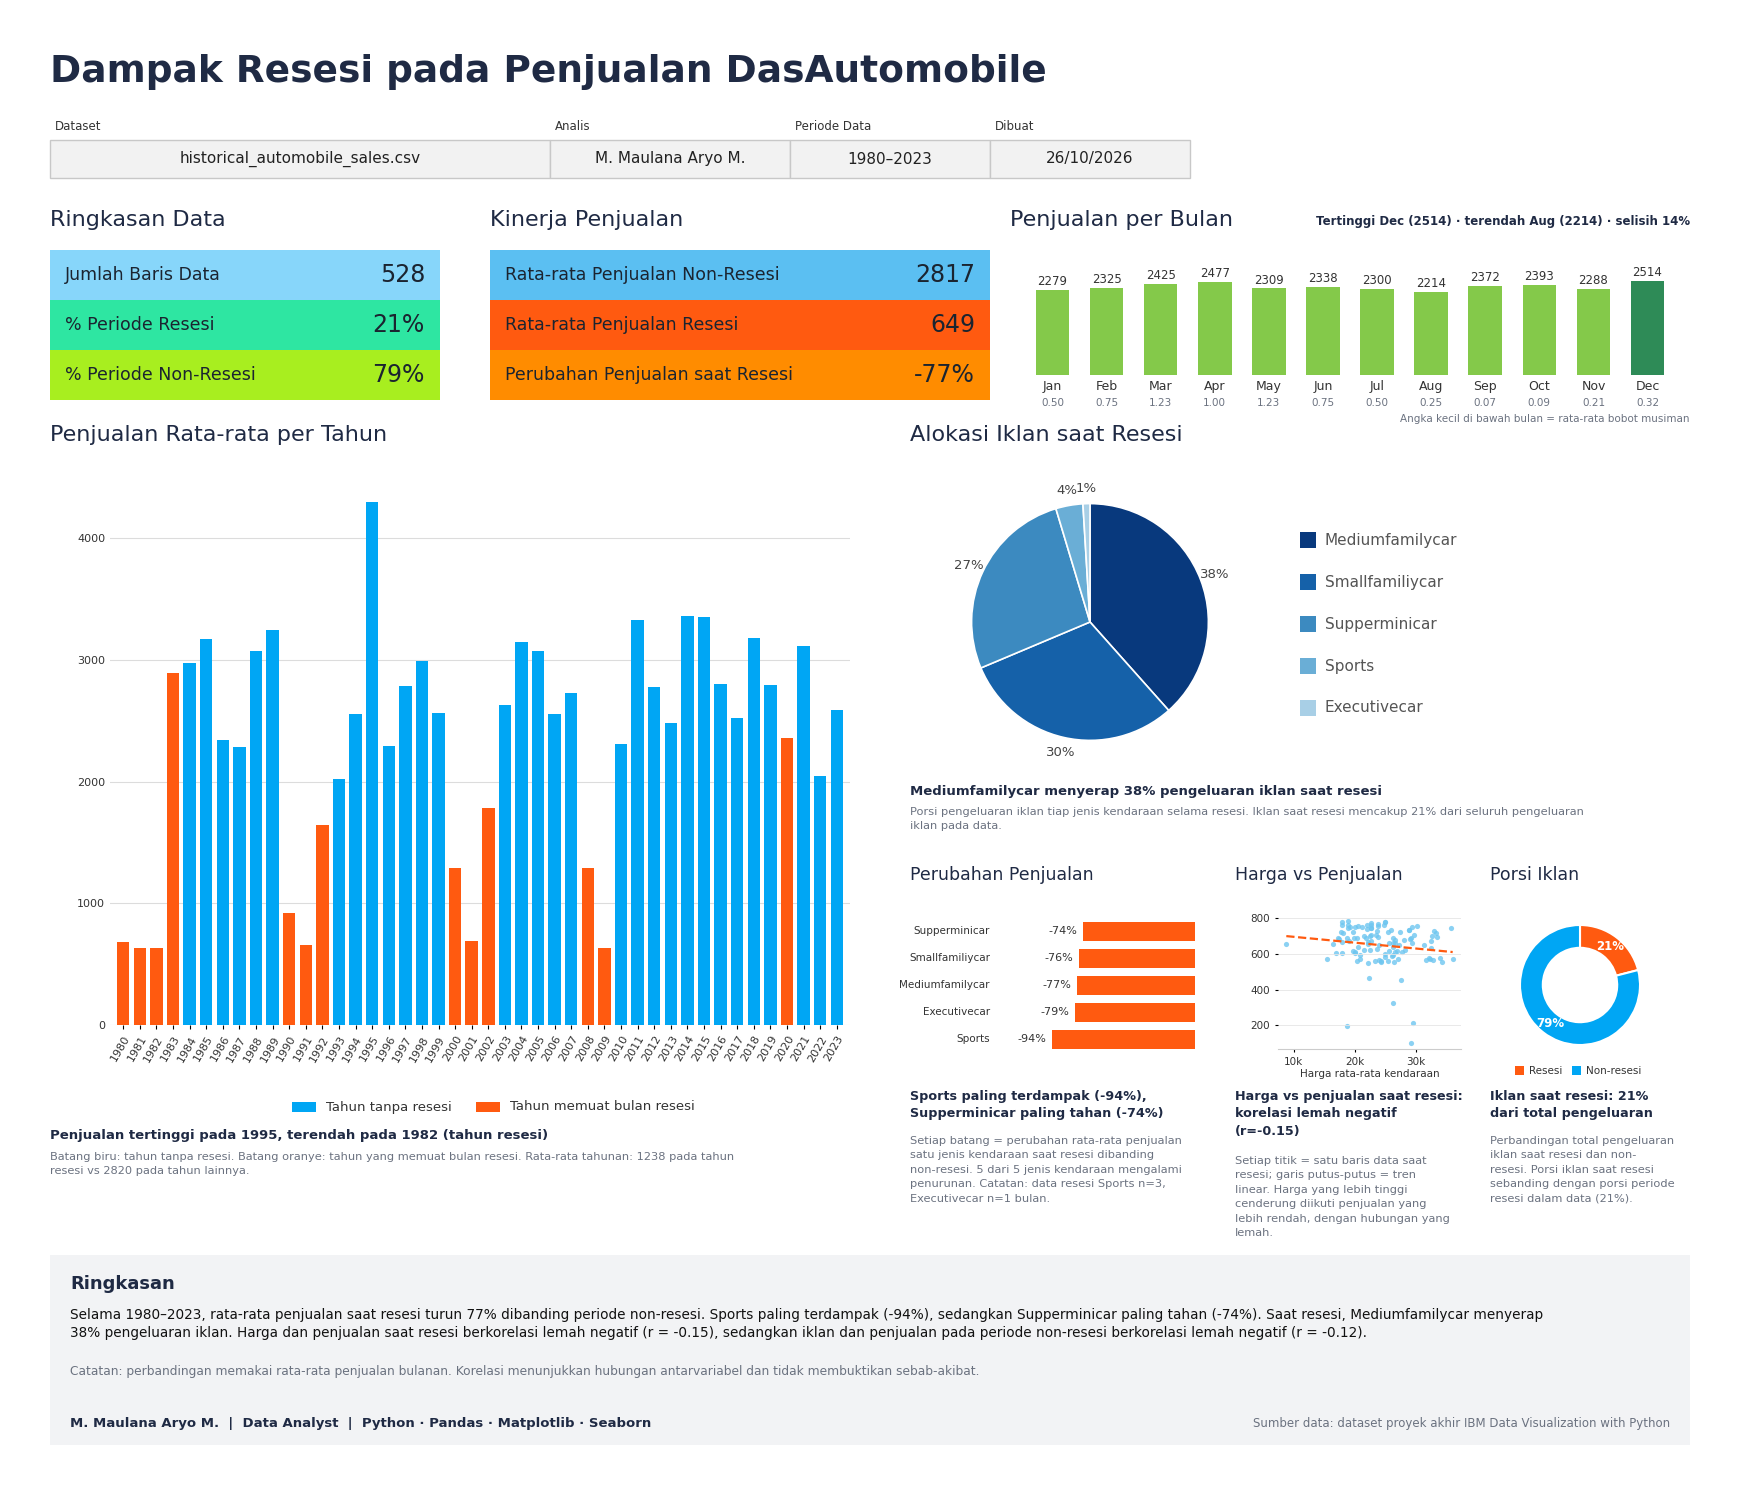

In [13]:
# ===== 3. Dashboard ringkasan: Dampak Resesi pada Penjualan DasAutomobile =====
# Seluruh angka berasal dari hasil bagian 1 dan ringkasan bagian 2 (jalankan keduanya lebih dulu).
import os, datetime, textwrap
from matplotlib.patches import Rectangle
from matplotlib.ticker import MultipleLocator, FuncFormatter

ANALIS = "M. Maulana Aryo M."
TAMPILKAN_CATATAN_N = True   # catatan jumlah bulan resesi (n) untuk jenis kendaraan yang datanya sedikit

# Palet & ukuran kanvas (koordinat dalam piksel, titik (0,0) di kiri-atas)
NAVY, GRAY, PANEL = "#1f2a44", "#6b7280", "#f2f3f5"
C_REC, C_NON = "#ff5a10", "#00a6f4"
BLUES = ["#08397d", "#1561a9", "#3c8ac0", "#6aaed6", "#a8cfe6"]
W, H = 1720, 1475


def buat_dashboard():
    fig = plt.figure(figsize=(W / 100, H / 100), dpi=100, facecolor="white")
    bg = fig.add_axes([0, 0, 1, 1]); bg.set_xlim(0, W); bg.set_ylim(H, 0); bg.axis("off")

    def ax_px(x, y, w, h):
        a = fig.add_axes([x / W, 1 - (y + h) / H, w / W, h / H]); a.patch.set_alpha(0); return a

    def T(x, y, s, size=10, color=NAVY, weight="normal", ha="left", va="center", **kw):
        bg.text(x, y, s, fontsize=size, color=color, fontweight=weight, ha=ha, va=va, **kw)

    def paragraf(x, y, s, width, size, color, weight="normal", gap=1.55):
        T(x, y, textwrap.fill(s, width), size, color, weight, va="top", linespacing=gap)

    # --- Judul & metadata ---
    T(40, 62, "Dampak Resesi pada Penjualan DasAutomobile", 27, NAVY, "bold")
    meta = [(40, 500, "Dataset", "historical_automobile_sales.csv"),
            (540, 240, "Analis", ANALIS),
            (780, 200, "Periode Data", f"{df['Year'].min()}–{df['Year'].max()}"),
            (980, 200, "Dibuat", datetime.date.today().strftime("%d/%m/%Y"))]
    for x, w, label, val in meta:
        T(x + 5, 116, label, 8.5, "#333")
        bg.add_patch(Rectangle((x, 130), w, 38, fc="#f2f2f2", ec="#c8c8c8", lw=1))
        T(x + w / 2, 149, val, 11, "#222", ha="center")

    # --- Judul seksi baris 1 ---
    T(40, 210, "Ringkasan Data", 16); T(480, 210, "Kinerja Penjualan", 16); T(1000, 210, "Penjualan per Bulan", 16)
    T(1680, 212, f"Tertinggi {best_month} ({season['Sales'].max():.0f}) · terendah {worst_month} ({season['Sales'].min():.0f}) · selisih {month_gap:.0f}%",
      8.5, NAVY, "bold", ha="right")

    # --- Kartu KPI ---
    def kpi_blok(x, w, baris):
        for i, (label, nilai, warna) in enumerate(baris):
            y = 240 + 50 * i
            bg.add_patch(Rectangle((x, y), w, 50, fc=warna, ec="none"))
            T(x + 15, y + 25, label, 12.5, "#1b2430"); T(x + w - 15, y + 25, nilai, 17, "#1b2430", ha="right")

    kpi_blok(40, 390, [("Jumlah Baris Data", f"{n_rows}", "#87d6fa"),
                       ("% Periode Resesi", f"{pct_rec:.0f}%", "#2ee6a2"),
                       ("% Periode Non-Resesi", f"{pct_non:.0f}%", "#a8ee1f")])
    kpi_blok(480, 500, [("Rata-rata Penjualan Non-Resesi", f"{avg_non:.0f}", "#5bbff2"),
                        ("Rata-rata Penjualan Resesi", f"{avg_rec:.0f}", C_REC),
                        ("Perubahan Penjualan saat Resesi", f"{chg_total:.0f}%", "#ff8c00")])

    # --- Penjualan per bulan + bobot musiman (bagian 1.5) ---
    ax = ax_px(1010, 250, 660, 115)
    warna_bulan = ["#2e8b57" if m == best_month else "#84c94a" for m in season.index]
    ax.bar(range(12), season["Sales"].values, width=0.62, color=warna_bulan)
    for i, v in enumerate(season["Sales"].values):
        ax.text(i, v + season["Sales"].max() * 0.02, f"{v:.0f}", ha="center", va="bottom", fontsize=8.5, color="#333")
    ax.set_xlim(-0.6, 11.6)
    ax.set_xticks(range(12)); ax.set_xticklabels(season.index, fontsize=9, color="#333")
    ax.set_ylim(0, season["Sales"].max() * 1.22); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)
    ax.tick_params(length=0)
    for i, w_ in enumerate(season["Seasonality"].values):          # bobot musiman di bawah nama bulan
        T(1010 + (i + 0.6) / 12.2 * 660, 393, f"{w_:.2f}", 7.5, GRAY, ha="center")
    T(1680, 409, "Angka kecil di bawah bulan = rata-rata bobot musiman", 7.5, GRAY, ha="right")

    # --- Penjualan rata-rata per tahun (bagian 1.1) ---
    T(40, 425, "Penjualan Rata-rata per Tahun", 16)
    ax = ax_px(100, 450, 740, 565)
    ax.bar(yearly_sales.index, yearly_sales.values, width=0.75,
           color=[C_REC if t else C_NON for t in yr_is_rec], zorder=3)
    ax.set_ylim(0, yearly_sales.max() * 1.08); ax.set_xlim(yearly_sales.index.min() - 0.8, yearly_sales.index.max() + 0.8)
    ax.yaxis.set_major_locator(MultipleLocator(1000)); ax.grid(axis="y", color="#dcdcdc", lw=0.8, zorder=0)
    ax.set_xticks(yearly_sales.index)
    ax.set_xticklabels(yearly_sales.index, rotation=60, ha="right", rotation_mode="anchor", fontsize=8, color="#333")
    ax.tick_params(axis="y", labelsize=8, labelcolor="#333", length=0); ax.tick_params(axis="x", length=3)
    for s in ax.spines.values(): s.set_visible(False)

    for x, warna, label in [(282, C_NON, "Tahun tanpa resesi"), (466, C_REC, "Tahun memuat bulan resesi")]:
        bg.add_patch(Rectangle((x, 1092), 24, 10, fc=warna, ec="none")); T(x + 34, 1097, label, 9.5, "#333")

    ket_tahun = "tahun resesi" if worst_year in set(recession_years) else "tahun tanpa resesi"
    T(40, 1126, f"Penjualan tertinggi pada {best_year}, terendah pada {worst_year} ({ket_tahun})", 9.5, NAVY, "bold")
    paragraf(40, 1142, f"Batang biru: tahun tanpa resesi. Batang oranye: tahun yang memuat bulan resesi. "
                       f"Rata-rata tahunan: {yr_avg_rec:.0f} pada tahun resesi vs {yr_avg_non:.0f} pada tahun lainnya.",
             118, 8.2, GRAY)

    # --- Alokasi iklan per jenis kendaraan saat resesi (bagian 1.8) ---
    T(900, 425, "Alokasi Iklan saat Resesi", 16)
    ax = ax_px(932, 464, 296, 296)
    ax.pie(rec_ad.values, startangle=90, counterclock=False, colors=BLUES[:len(rec_ad)],
           wedgeprops=dict(edgecolor="white", linewidth=1.2),
           autopct=lambda p: f"{p:.0f}%", pctdistance=1.13, textprops=dict(fontsize=9.5, color="#444"))
    for i, nama in enumerate(rec_ad.index):
        y = 530 + 42 * i
        bg.add_patch(Rectangle((1290, y - 8), 16, 16, fc=BLUES[i], ec="none")); T(1315, y, nama, 11, "#555")
    top_ad = rec_ad.index[0]
    T(900, 781, f"{top_ad} menyerap {vt_ad_pct.iloc[0]:.0f}% pengeluaran iklan saat resesi", 9.5, NAVY, "bold")
    paragraf(900, 797, f"Porsi pengeluaran iklan tiap jenis kendaraan selama resesi. Iklan saat resesi mencakup "
                       f"{ad_rec_pct:.0f}% dari seluruh pengeluaran iklan pada data.", 120, 8.2, GRAY)

    # --- Tiga panel kecil ---
    T(900, 865, "Perubahan Penjualan", 12.5); T(1225, 865, "Harga vs Penjualan", 12.5); T(1480, 865, "Porsi Iklan", 12.5)

    # (a) perubahan penjualan per jenis kendaraan (bagian 1.3)
    for i, (nama, chg) in enumerate(vt_chg.items()):
        y = 921 + 27 * i; lebar = min(abs(chg), 100) * 1.52
        bg.add_patch(Rectangle((1185 - lebar, y - 9.5), lebar, 19, fc=C_REC, ec="none"))
        T(1185 - lebar - 6, y, f"{chg:.0f}%", 8, "#333", ha="right"); T(980, y, nama, 7.5, "#333", ha="right")

    # (b) harga vs penjualan saat resesi + garis tren linear (bagian 1.6)
    ax = ax_px(1268, 905, 183, 134)
    ax.scatter(rec["Price"], rec["Automobile_Sales"], s=14, color="#6ec6f0", alpha=0.8, lw=0)
    koef = np.polyfit(rec["Price"], rec["Automobile_Sales"], 1)
    xs = np.array([rec["Price"].min(), rec["Price"].max()])
    ax.plot(xs, np.polyval(koef, xs), color=C_REC, ls="--", lw=1.6)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
    ax.set_xlabel("Harga rata-rata kendaraan", fontsize=7.5, color="#333", labelpad=2)
    ax.tick_params(labelsize=7.5, labelcolor="#333", length=2); ax.grid(axis="y", color="#e5e5e5", lw=0.6)
    for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color("#cccccc")

    # (c) donat porsi iklan resesi vs non-resesi (bagian 1.7)
    ax = ax_px(1495, 900, 150, 150)
    ax.pie([ad_rec_pct, 100 - ad_rec_pct], startangle=90, counterclock=False, colors=[C_REC, C_NON],
           wedgeprops=dict(width=0.38, edgecolor="white", linewidth=1.5),
           autopct=lambda p: f"{p:.0f}%", pctdistance=0.81, textprops=dict(fontsize=8.5, color="white", fontweight="bold"))
    for x, warna, label in [(1505, C_REC, "Resesi"), (1562, C_NON, "Non-resesi")]:
        bg.add_patch(Rectangle((x, 1056), 9, 9, fc=warna, ec="none")); T(x + 14, 1061, label, 7.5, "#333")

    # Keterangan di bawah tiga panel
    t_atas, t_bawah = vt_chg.index[0], vt_chg.index[-1]
    paragraf(900, 1080, f"{t_bawah} paling terdampak ({vt_chg.iloc[-1]:.0f}%), {t_atas} paling tahan ({vt_chg.iloc[0]:.0f}%)",
             36, 9.2, NAVY, "bold", 1.45)
    ket = (f"Setiap batang = perubahan rata-rata penjualan satu jenis kendaraan saat resesi dibanding non-resesi. "
           f"{(vt_chg < 0).sum()} dari {len(vt_chg)} jenis kendaraan mengalami penurunan.")
    if TAMPILKAN_CATATAN_N:
        sedikit = vt_n[vt_n < 10]
        if len(sedikit):
            ket += " Catatan: data resesi " + ", ".join(f"{k} n={v}" for k, v in sedikit.items()) + " bulan."
    paragraf(900, 1126, ket, 46, 8.2, GRAY)

    arah = "lebih rendah" if r_price < 0 else "lebih tinggi"
    paragraf(1225, 1080, f"Harga vs penjualan saat resesi: korelasi {label_korelasi(r_price)} (r={r_price:.2f})",
             31, 9.2, NAVY, "bold", 1.45)
    paragraf(1225, 1146, f"Setiap titik = satu baris data saat resesi; garis putus-putus = tren linear. "
                         f"Harga yang lebih tinggi cenderung diikuti penjualan yang {arah}, dengan hubungan yang {kekuatan_korelasi(r_price)}.",
             35, 8.2, GRAY)

    paragraf(1480, 1080, f"Iklan saat resesi: {ad_rec_pct:.0f}% dari total pengeluaran", 25, 9.2, NAVY, "bold", 1.45)
    paragraf(1480, 1126, f"Perbandingan total pengeluaran iklan saat resesi dan non-resesi. Porsi iklan saat resesi "
                         f"sebanding dengan porsi periode resesi dalam data ({pct_rec:.0f}%).", 31, 8.2, GRAY)

    # --- Ringkasan ---
    bg.add_patch(Rectangle((40, 1245), 1640, 190, fc=PANEL, ec="none"))
    T(60, 1274, "Ringkasan", 13, NAVY, "bold")
    ringkasan_teks = (
        f"Selama {df['Year'].min()}–{df['Year'].max()}, rata-rata penjualan saat resesi turun {abs(chg_total):.0f}% dibanding periode non-resesi. "
        f"{t_bawah} paling terdampak ({vt_chg.iloc[-1]:.0f}%), sedangkan {t_atas} paling tahan ({vt_chg.iloc[0]:.0f}%). "
        f"Saat resesi, {top_ad} menyerap {vt_ad_pct.iloc[0]:.0f}% pengeluaran iklan. "
        f"Harga dan penjualan saat resesi berkorelasi {label_korelasi(r_price)} (r = {r_price:.2f}), "
        f"sedangkan iklan dan penjualan pada periode non-resesi berkorelasi {label_korelasi(r_ad)} (r = {r_ad:.2f}).")
    paragraf(60, 1298, ringkasan_teks, 205, 9.8, "#111", gap=1.35)
    T(60, 1362, "Catatan: perbandingan memakai rata-rata penjualan bulanan. Korelasi menunjukkan hubungan antarvariabel dan tidak membuktikan sebab-akibat.",
      8.8, GRAY)
    T(60, 1413, f"{ANALIS}  |  Data Analyst  |  Python · Pandas · Matplotlib · Seaborn", 9.5, NAVY, "bold")
    T(1660, 1413, "Sumber data: dataset proyek akhir IBM Data Visualization with Python", 8.5, GRAY, ha="right")
    return fig


# style 'default' agar dashboard tidak terpengaruh tema seaborn (whitegrid) dari sel awal
with plt.style.context("default"):
    fig = buat_dashboard()
    os.makedirs("images", exist_ok=True)
    fig.savefig("images/dashboard.png", dpi=100, facecolor="white")
    plt.show()

## Catatan akhir
Jalankan **Kernel > Restart & Run All** sebelum menyimpan, supaya semua grafik, angka ringkasan, dan dashboard tersimpan di dalam notebook yang diunggah. Dashboard akan tersimpan otomatis ke `images/dashboard.png`.